In [89]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression


In [90]:
# Creation de donnee 
x,y = make_regression(n_samples= 100, n_features= 2, noise = 23)


In [91]:
x.shape

(100, 2)

In [92]:
y.shape

(100,)

In [93]:
y = y.reshape(-1, 1)

In [94]:
y.shape

(100, 1)

In [95]:
# Creation de theta
theta = np.random.randn(3, 1)

In [96]:
theta.shape

(3, 1)

In [97]:
#Creation de la matrice X
ones = np.ones((x.shape[0],1))
X = np.hstack((x , ones ))

In [98]:
X.shape

(100, 3)

In [99]:
# Modele  lineaire 
def modele(X, theta):
    return X @ theta

In [100]:
modele(X, theta).shape

(100, 1)

ValueError: x and y must be the same size

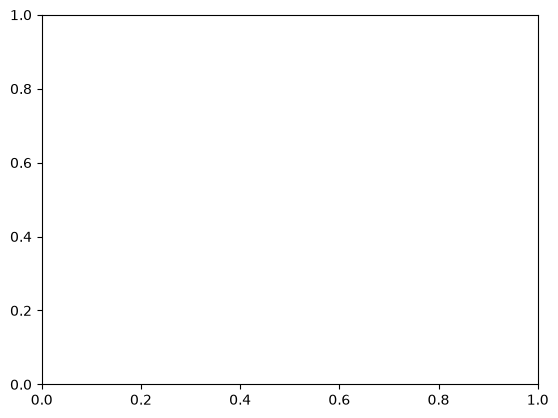

In [101]:
# Afichage 
plt.scatter(x, y, label="Données réelles")

plt.plot(
    x,
    modele(X, new_theta),
    color="red",
    label="Droite de régression"
)

In [ ]:
# Fonction cout 
def fonction_cout(X, y, theta):
    m = len(y)
    return (1 / (2*m )) * np.sum((modele(X, theta) - y)**2)

In [102]:
def gradient(X, theta, y):
    m = len(y)
    return (1 / m) * X.T @ (modele(X, theta) - y)

In [103]:
 gradient(X, theta, y ).shape

(3, 1)

In [118]:

def descente_gradient(X, theta, alpha, y, n_iteration):

    for i in range(n_iteration):
        theta = theta - alpha * gradient(X, theta, y)

    return theta

In [119]:
# Entrainement 

In [123]:
new_theta =  descente_gradient(X, theta, 0.01, y, 1000)

In [124]:
print("Cout initial :", fonction_cout(X, y, theta) )
print("Cout final : ", fonction_cout(X, y, new_theta) )

Cout initial : 4587.970526177055
Cout final :  300.3412438622526


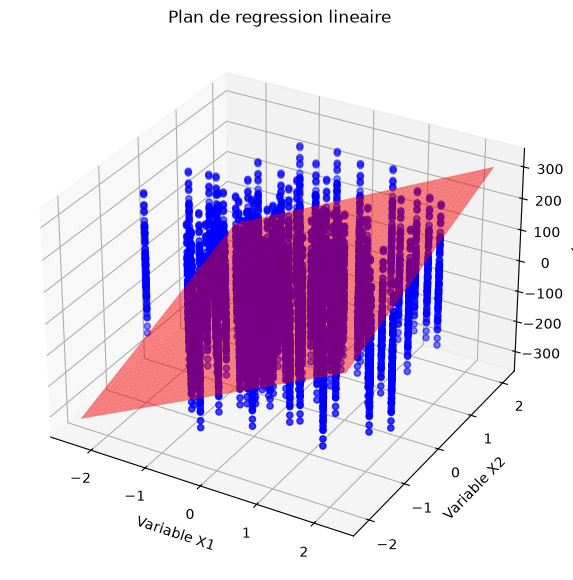

In [127]:
# Affichage du plan de regression en 3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Donnees reelles
ax.scatter(x[:, 0], x[:, 1], y, color='blue', label='Données réelles')

# Creation de la surface
x1 = np.linspace(x[:, 0].min(), x[:, 0].max(), 50)
x2 = np.linspace(x[:, 1].min(), x[:, 1].max(), 50)

X1, X2 = np.meshgrid(x1, x2)

Y_pred = (new_theta[0] * X1 +
          new_theta[1] * X2 +
          new_theta[2])

# Affichage du plan
ax.plot_surface(X1, X2, Y_pred, alpha=0.5, color='red')

ax.set_xlabel('Variable X1')
ax.set_ylabel('Variable X2')
ax.set_zlabel('Y')
ax.set_title('Plan de regression lineaire')

plt.show()